In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


In [3]:
patches_image_dir = Path("../data/raw/patches_64/images")
patches_mask_dir = Path("../data/raw/patches_64/masks")

image_patch_files = sorted(patches_image_dir.glob("*.npy"))
mask_patch_files = sorted(patches_mask_dir.glob("*.npy"))

print(f"Total image patches: {len(image_patch_files)}")
print(f"Total mask patches: {len(mask_patch_files)}")
print(f"First 10 patch names:")
for f in image_patch_files[:10]:
    print(f"  {f.name}")



Total image patches: 2244
Total mask patches: 2244
First 10 patch names:
  patch_64_00000001.npy
  patch_64_00000002.npy
  patch_64_00000003.npy
  patch_64_00000004.npy
  patch_64_00000005.npy
  patch_64_00000006.npy
  patch_64_00000007.npy
  patch_64_00000008.npy
  patch_64_00000009.npy
  patch_64_00000010.npy


In [4]:
patch_idx = 0
image_patch = np.load(image_patch_files[patch_idx])
mask_patch = np.load(mask_patch_files[patch_idx])

print(f"Patch {patch_idx} - {image_patch_files[patch_idx].name}")
print(f"Image patch shape: {image_patch.shape}")
print(f"Image patch dtype: {image_patch.dtype}")
print(f"Image patch min: {image_patch.min():.4f}, max: {image_patch.max():.4f}")
print()
print(f"Mask patch shape: {mask_patch.shape}")
print(f"Mask patch dtype: {mask_patch.dtype}")
print(f"Mask patch unique values: {np.unique(mask_patch)}")
print(f"Number of neurons in this patch: {mask_patch.sum()}")

Patch 0 - patch_64_00000001.npy
Image patch shape: (64, 64, 64)
Image patch dtype: uint16
Image patch min: 224.0000, max: 706.0000

Mask patch shape: (64, 64, 64)
Mask patch dtype: uint8
Mask patch unique values: [  0 255]
Number of neurons in this patch: 171615


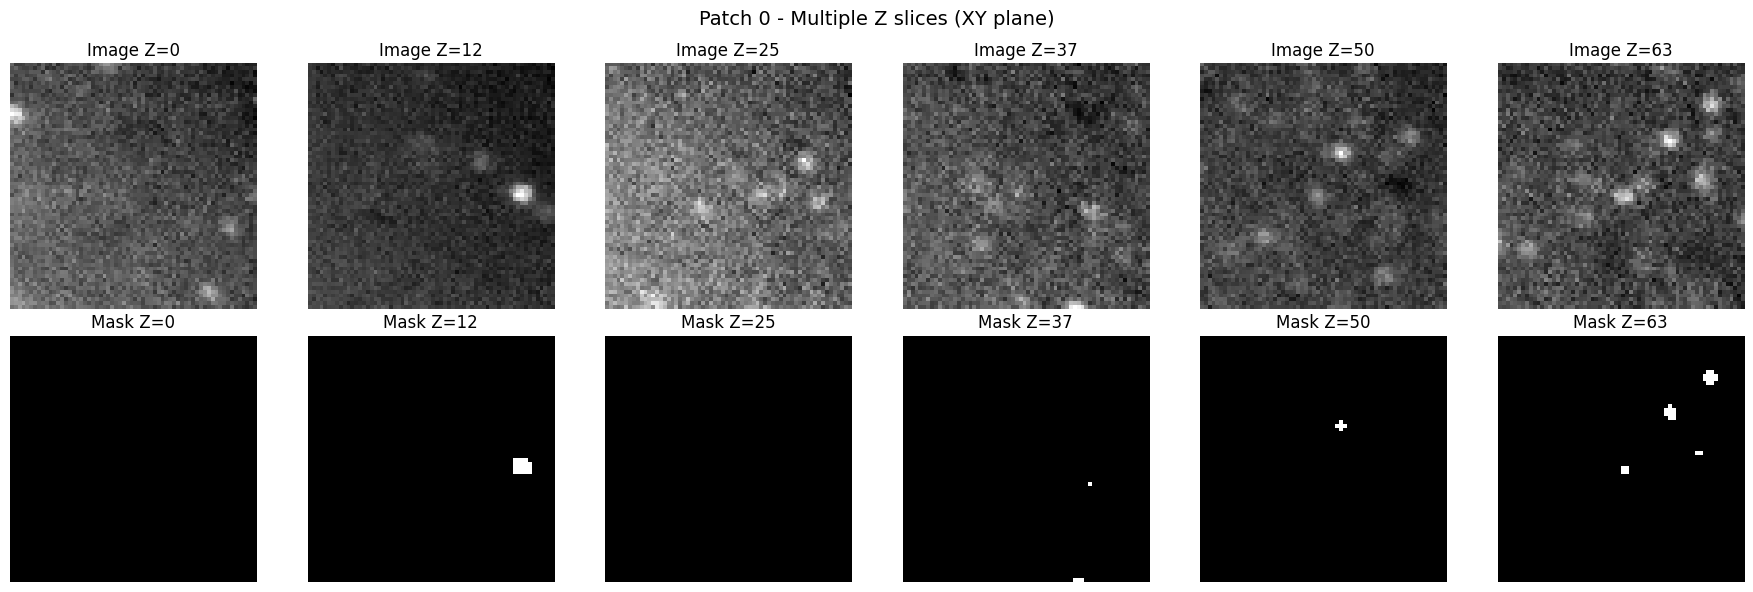

In [5]:
patch_idx = 0
image_patch = np.load(image_patch_files[patch_idx])
mask_patch = np.load(mask_patch_files[patch_idx])

num_slices = 6
total_z = image_patch.shape[0]
slice_indices = np.linspace(0, total_z - 1, num_slices, dtype=int)

fig, axes = plt.subplots(2, num_slices, figsize=(18, 6))

for i, z_idx in enumerate(slice_indices):
    # Image slice
    axes[0, i].imshow(image_patch[z_idx, :, :], cmap='gray')
    axes[0, i].set_title(f'Image Z={z_idx}')
    axes[0, i].axis('off')
    
    # Mask slice
    axes[1, i].imshow(mask_patch[z_idx, :, :], cmap='gray')
    axes[1, i].set_title(f'Mask Z={z_idx}')
    axes[1, i].axis('off')

plt.suptitle(f'Patch {patch_idx} - Multiple Z slices (XY plane)', fontsize=14)
plt.tight_layout()
plt.show()

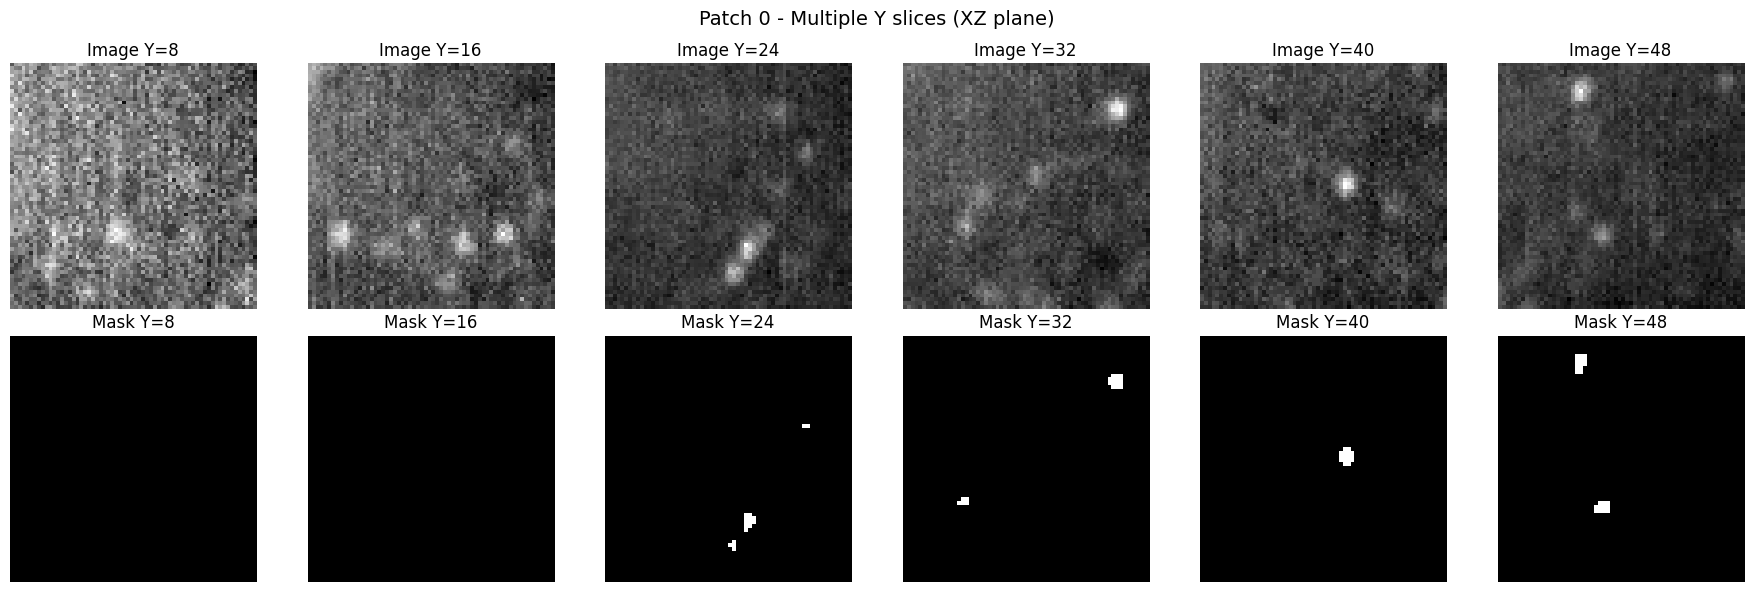

In [6]:
patch_idx = 0
image_patch = np.load(image_patch_files[patch_idx])
mask_patch = np.load(mask_patch_files[patch_idx])

total_y = image_patch.shape[1]
y_indices = [8, 16, 24, 32, 40, 48]  

fig, axes = plt.subplots(2, len(y_indices), figsize=(18, 6))

for i, y_idx in enumerate(y_indices):
    axes[0, i].imshow(image_patch[:, y_idx, :], cmap='gray')
    axes[0, i].set_title(f'Image Y={y_idx}')
    axes[0, i].axis('off')

    axes[1, i].imshow(mask_patch[:, y_idx, :], cmap='gray')
    axes[1, i].set_title(f'Mask Y={y_idx}')
    axes[1, i].axis('off')

plt.suptitle(f'Patch {patch_idx} - Multiple Y slices (XZ plane)', fontsize=14)
plt.tight_layout()
plt.show()

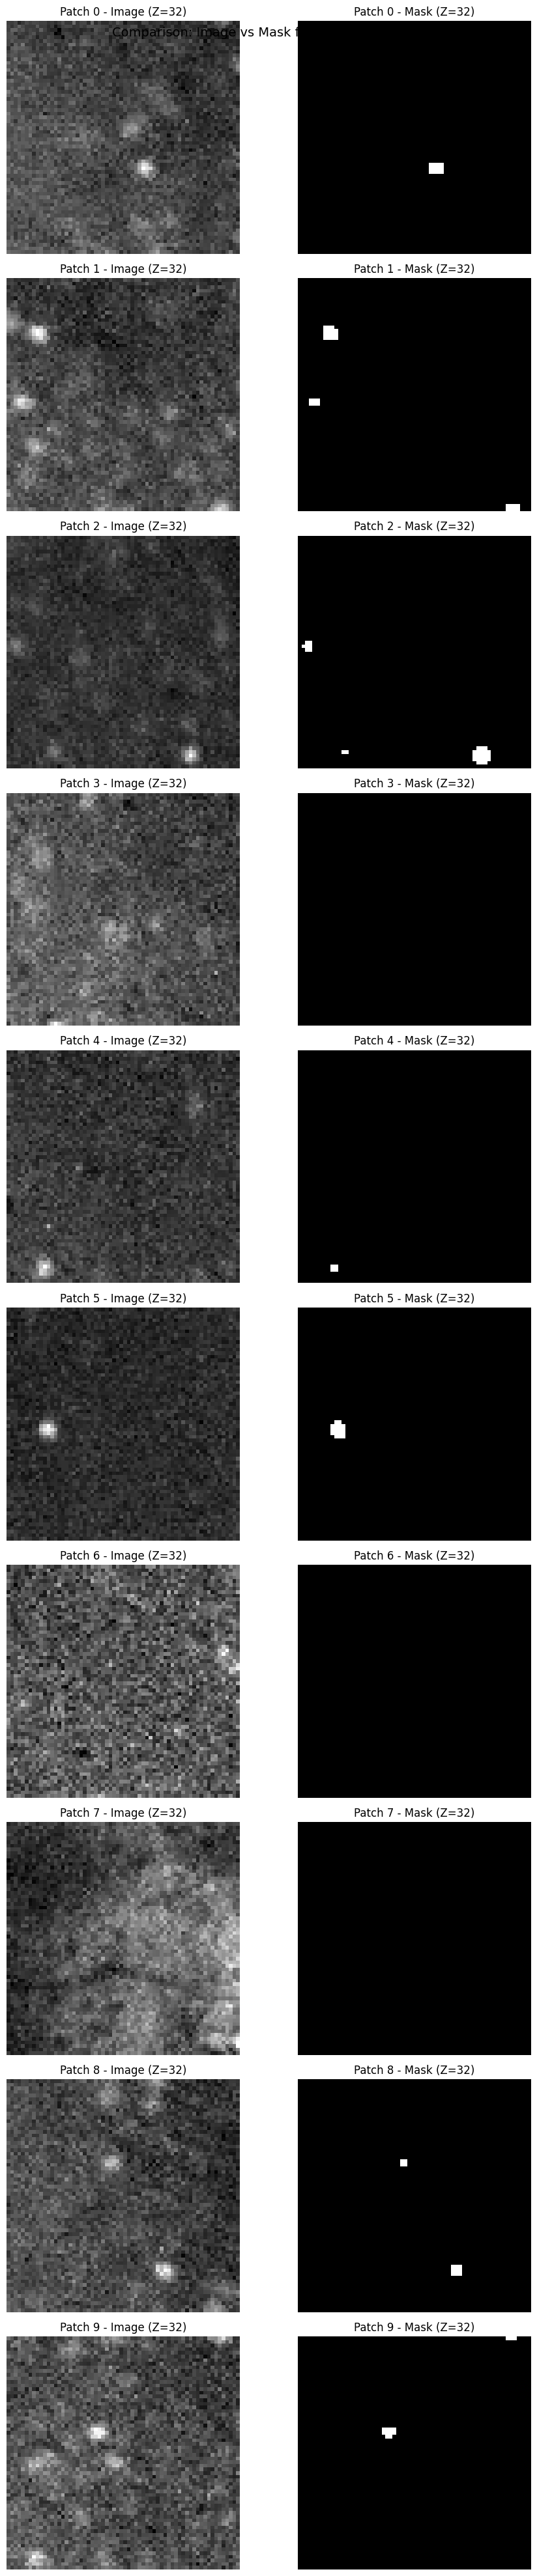

In [15]:
num_patches_to_show = 10
middle_z = 32 

fig, axes = plt.subplots(num_patches_to_show, 2, figsize=(10, 4 * num_patches_to_show))

for i in range(num_patches_to_show):
    image_patch = np.load(image_patch_files[i])
    mask_patch = np.load(mask_patch_files[i])
    
    # Image
    axes[i, 0].imshow(image_patch[middle_z, :, :], cmap='gray')
    axes[i, 0].set_title(f'Patch {i} - Image (Z={middle_z})')
    axes[i, 0].axis('off')
    
    # Mask
    axes[i, 1].imshow(mask_patch[middle_z, :, :], cmap='gray')
    axes[i, 1].set_title(f'Patch {i} - Mask (Z={middle_z})')
    axes[i, 1].axis('off')

plt.suptitle('Comparison: Image vs Mask for different patches', fontsize=14)
plt.tight_layout()
plt.show()

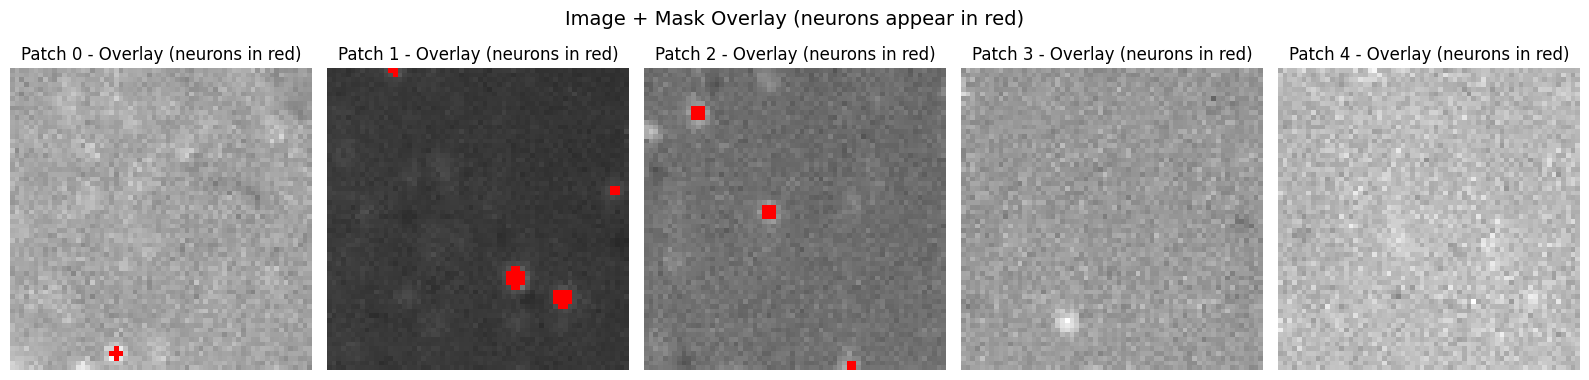

In [18]:
num_patches_to_show = 5
middle_z = 32

fig, axes = plt.subplots(1, num_patches_to_show, figsize=(16, 4))

for i in range(num_patches_to_show):
    image_patch = np.load(image_patch_files[i+10])
    mask_patch = np.load(mask_patch_files[i+10])
    

    img_slice = image_patch[middle_z, :, :]
    msk_slice = mask_patch[middle_z, :, :]
    

    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()

    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[msk_slice > 0, 0] = 1  # Red channel
    overlay[msk_slice > 0, 1] = 0  # Green channel
    overlay[msk_slice > 0, 2] = 0  # Blue channel
    
    axes[i].imshow(overlay)
    axes[i].set_title(f'Patch {i} - Overlay (neurons in red)')
    axes[i].axis('off')

plt.suptitle('Image + Mask Overlay (neurons appear in red)', fontsize=14)
plt.tight_layout()
plt.show()

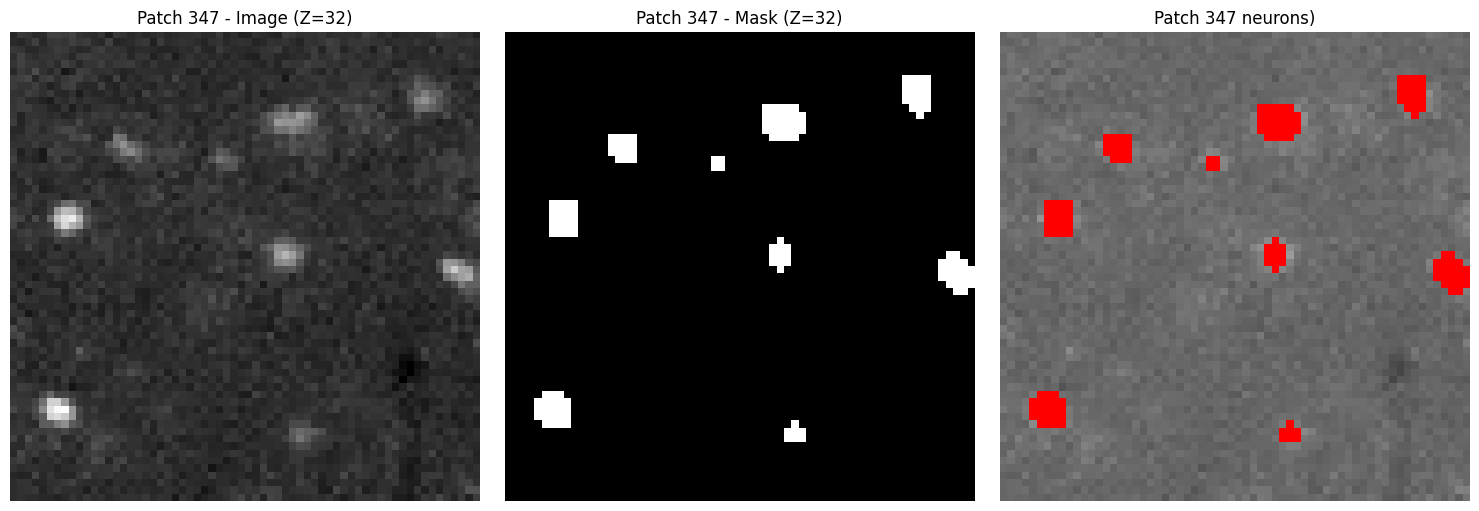

In [11]:
if np.sum(neurons_per_patch > 0) > 0:
    idx_max = np.argmax(neurons_per_patch)
    image_patch = np.load(image_patch_files[idx_max])
    mask_patch = np.load(mask_patch_files[idx_max])
    middle_z = image_patch.shape[0] // 2
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
    
    ax1.imshow(image_patch[middle_z, :, :], cmap='gray')
    ax1.set_title(f'Patch {idx_max} - Image (Z={middle_z})')
    ax1.axis('off')
    
    ax2.imshow(mask_patch[middle_z, :, :], cmap='gray')
    ax2.set_title(f'Patch {idx_max} - Mask (Z={middle_z})')
    ax2.axis('off')
    
    # Overlay
    img_slice = image_patch[middle_z, :, :]
    msk_slice = mask_patch[middle_z, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[msk_slice > 0, 0] = 1
    overlay[msk_slice > 0, 1] = 0
    overlay[msk_slice > 0, 2] = 0
    
    ax3.imshow(overlay)
    ax3.set_title(f'Patch {idx_max} neurons)')
    ax3.axis('off')
    
    plt.tight_layout()
    plt.show()